In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
X_train = pd.read_csv("data/cleaned/X_train_scaled.csv")
y_train = pd.read_csv("data/cleaned/y_train.csv")
X_val = pd.read_csv("data/cleaned/X_val_scaled.csv")
y_val = pd.read_csv("data/cleaned/y_val.csv")

In [3]:
X_train.head()

,Unnamed: 0,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Admission grade,Debtor,Tuition fees up to date,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,302,-1.001238,-0.557817,0.118266,0.338841,-0.356076,1.150926,0.665038,-0.352750,0.369896,...,-0.215555,-0.283696,-0.099033,0.255481,0.516987,0.722844,-0.194475,1.489361,1.159936,-1.798439
1,1421,-1.001238,-0.557817,0.134349,0.338841,-0.356076,-0.511985,0.231693,-0.352750,0.369896,...,-0.215555,-0.283696,-0.546486,-0.000413,-0.471476,0.339383,-0.194475,-0.284495,0.145043,0.760121
2,274,1.855816,-0.557817,0.147594,0.338841,1.370943,0.024682,-1.013313,2.834871,-2.703465,...,-0.215555,-0.283696,-0.546486,-0.768096,-1.459940,-1.961380,-0.194475,-1.001586,0.145043,1.540923
3,258,-0.086981,0.984511,0.314572,0.338841,-0.356076,-0.058464,0.272964,-0.352750,0.369896,...,-0.215555,-0.283696,0.795875,-0.000413,0.846475,0.661764,-0.194475,-0.284495,0.145043,0.760121
4,484,1.455829,-0.557817,0.079478,0.338841,3.289853,2.057968,2.281482,-0.352750,0.369896,...,-0.215555,-0.283696,-0.099033,0.255481,0.516987,0.476334,-0.194475,0.319371,-0.507388,0.782177


In [4]:
y_train.head()

,Unnamed: 0,Target
0,302,Graduate
1,1421,Enrolled
2,274,Dropout
3,258,Enrolled
4,484,Graduate


In [5]:
X_train = X_train.drop(columns=["Unnamed: 0"], errors="ignore")
X_val = X_val.drop(columns=["Unnamed: 0"], errors="ignore")
y_train = y_train.drop(columns=["Unnamed: 0"], errors="ignore")
y_val = y_val.drop(columns=["Unnamed: 0"], errors="ignore")

In [6]:
# Ubah ke numpy
X_train = X_train.values.astype(float)
X_val = X_val.values.astype(float)

In [7]:
classes = sorted(y_train['Target'].unique())
label_to_idx = {label: idx for idx, label in enumerate(classes)}
idx_to_label = {idx: label for label, idx in label_to_idx.items()}

In [8]:
y_train_idx = y_train['Target'].map(label_to_idx).values
y_val_idx = y_val['Target'].map(label_to_idx).values

In [9]:
num_classes = len(classes)
y_train_oh = np.eye(num_classes)[y_train_idx]
y_val_oh = np.eye(num_classes)[y_val_idx]

In [10]:
print(f"Classes mapping : {label_to_idx}")
print(f"X_train shape   : {X_train.shape}, y_train_oh shape: {y_train_oh.shape}")
print(f"X_val shape     : {X_val.shape}, y_val_oh shape  : {y_val_oh.shape}")

Classes mapping : {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
X_train shape   : (2476, 25), y_train_oh shape: (2476, 3)
X_val shape     : (620, 25), y_val_oh shape  : (620, 3)


In [11]:
class Activations:
    @staticmethod
    def relu(Z):
        return np.maximum(0, Z)

    @staticmethod
    def relu_derivative(Z):
        return (Z > 0).astype(np.float64)

    @staticmethod
    def leaky_relu(Z, alpha=0.01):
        return np.where(Z > 0, Z, alpha * Z)

    @staticmethod
    def leaky_relu_derivative(Z, alpha=0.01):
        return np.where(Z > 0, 1.0, alpha)

    @staticmethod
    def sigmoid(Z):
        Z_clipped = np.clip(Z, -500, 500)
        return 1.0 / (1.0 + np.exp(-Z_clipped))

    @staticmethod
    def sigmoid_derivative(Z):
        s = Activations.sigmoid(Z)
        return s * (1.0 - s)

    @staticmethod
    def tanh(Z):
        return np.tanh(Z)

    @staticmethod
    def tanh_derivative(Z):
        return 1.0 - np.tanh(Z) ** 2

    @staticmethod
    def softmax(Z):
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

In [12]:
class ArtificialNeuralNetwork:
    def __init__(
        self,
        input_dim,
        hidden_layers=(64, 32),
        output_dim=3,
        activations='relu',
        learning_rate=0.01,
        epochs=100,
        batch_size=32,
        l2_lambda=0.0,
        random_state=42
    ):
        self.input_dim = input_dim
        self.hidden_layers = list(hidden_layers)
        self.output_dim = output_dim
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.l2_lambda = l2_lambda
        self.random_state = random_state
        if isinstance(activations, str):
            self.activations = [activations.lower()] * len(self.hidden_layers)
        else:
            if len(activations) != len(self.hidden_layers):
                raise ValueError("Length of activations must match number of hidden layers.")
            self.activations = [act.lower() for act in activations]
        self.layer_dims = [self.input_dim] + self.hidden_layers + [self.output_dim]
        self.num_layers = len(self.layer_dims) - 1  # Number of weight matrices
        self.weights = {}
        self.biases = {}
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
        self._initialize_parameters()

    def _initialize_parameters(self):
        rng = np.random.default_rng(self.random_state)
        for l in range(1, self.num_layers + 1):
            in_dim = self.layer_dims[l - 1]
            out_dim = self.layer_dims[l]

            if l <= len(self.activations) and self.activations[l - 1] in ('relu', 'leaky_relu'):
                std = np.sqrt(2.0 / in_dim)
            else:
                std = np.sqrt(1.0 / in_dim)

            self.weights[l] = rng.normal(0.0, std, size=(in_dim, out_dim))
            self.biases[l] = np.zeros((1, out_dim), dtype=np.float64)

    def _apply_activation(self, Z, name):
        if name == 'relu':
            return Activations.relu(Z)
        elif name == 'leaky_relu':
            return Activations.leaky_relu(Z)
        elif name == 'sigmoid':
            return Activations.sigmoid(Z)
        elif name == 'tanh':
            return Activations.tanh(Z)
        elif name == 'softmax':
            return Activations.softmax(Z)
        else:
            raise ValueError(f"Unsupported activation function: {name}")

    def _apply_activation_derivative(self, Z, name):
        if name == 'relu':
            return Activations.relu_derivative(Z)
        elif name == 'leaky_relu':
            return Activations.leaky_relu_derivative(Z)
        elif name == 'sigmoid':
            return Activations.sigmoid_derivative(Z)
        elif name == 'tanh':
            return Activations.tanh_derivative(Z)
        else:
            raise ValueError(f"Unsupported activation derivative: {name}")

    def forward(self, X):
        """Perform forward propagation across all layers and cache intermediate values."""
        cache = {'A0': X}
        A = X
        for l in range(1, self.num_layers):
            Z = A @ self.weights[l] + self.biases[l]
            A = self._apply_activation(Z, self.activations[l - 1])
            cache[f'Z{l}'] = Z
            cache[f'A{l}'] = A
        L = self.num_layers
        ZL = A @ self.weights[L] + self.biases[L]
        AL = Activations.softmax(ZL)
        cache[f'Z{L}'] = ZL
        cache[f'A{L}'] = AL
        return AL, cache

    def compute_loss(self, y_true_oh, y_pred_probs):
        m = y_true_oh.shape[0]
        eps = 1e-12
        probs_clipped = np.clip(y_pred_probs, eps, 1.0 - eps)
        ce_loss = -np.sum(y_true_oh * np.log(probs_clipped)) / m
        if self.l2_lambda > 0:
            l2_cost = (self.l2_lambda / (2 * m)) * sum(
                np.sum(np.square(self.weights[l])) for l in range(1, self.num_layers + 1)
            )
            return ce_loss + l2_cost
        return ce_loss

    def backward(self, y_true_oh, cache):
        m = y_true_oh.shape[0]
        grads_W = {}
        grads_b = {}
        L = self.num_layers
        dZ = (cache[f'A{L}'] - y_true_oh) / m
        grads_W[L] = cache[f'A{L - 1}'].T @ dZ + (self.l2_lambda / m) * self.weights[L]
        grads_b[L] = np.sum(dZ, axis=0, keepdims=True)
        for l in range(L - 1, 0, -1):
            dA = dZ @ self.weights[l + 1].T
            dZ = dA * self._apply_activation_derivative(cache[f'Z{l}'], self.activations[l - 1])
            grads_W[l] = cache[f'A{l - 1}'].T @ dZ + (self.l2_lambda / m) * self.weights[l]
            grads_b[l] = np.sum(dZ, axis=0, keepdims=True)

        return grads_W, grads_b

    def _update_parameters(self, grads_W, grads_b):
        for l in range(1, self.num_layers + 1):
            self.weights[l] -= self.learning_rate * grads_W[l]
            self.biases[l] -= self.learning_rate * grads_b[l]

    def fit(self, X_train, y_train_oh, X_val=None, y_val_oh=None, verbose=True):
        rng = np.random.default_rng(self.random_state)
        n_samples = X_train.shape[0]
        for epoch in range(1, self.epochs + 1):
            # Shuffle training data each epoch
            indices = rng.permutation(n_samples)
            X_shuffled = X_train[indices]
            y_shuffled = y_train_oh[indices]
            for start in range(0, n_samples, self.batch_size):
                end = start + self.batch_size
                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]
                _, cache = self.forward(X_batch)
                grads_W, grads_b = self.backward(y_batch, cache)
                self._update_parameters(grads_W, grads_b)
            train_probs, _ = self.forward(X_train)
            train_loss = self.compute_loss(y_train_oh, train_probs)
            train_acc = np.mean(np.argmax(train_probs, axis=1) == np.argmax(y_train_oh, axis=1))
            self.history['train_loss'].append(train_loss)
            self.history['train_acc'].append(train_acc)
            if X_val is not None and y_val_oh is not None:
                val_probs, _ = self.forward(X_val)
                val_loss = self.compute_loss(y_val_oh, val_probs)
                val_acc = np.mean(np.argmax(val_probs, axis=1) == np.argmax(y_val_oh, axis=1))
                self.history['val_loss'].append(val_loss)
                self.history['val_acc'].append(val_acc)
                if verbose and (epoch % 10 == 0 or epoch == 1 or epoch == self.epochs):
                    print(
                        f"Epoch {epoch:3d}/{self.epochs} | "
                        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
                        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
                    )
            else:
                if verbose and (epoch % 10 == 0 or epoch == 1 or epoch == self.epochs):
                    print(
                        f"Epoch {epoch:3d}/{self.epochs} | "
                        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}"
                    )
        return self

    def predict_proba(self, X):
        probs, _ = self.forward(X)
        return probs

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

In [ ]:
def gradient_check(model, X_sample, y_sample_oh, epsilon=1e-7):
    _, cache = model.forward(X_sample)
    grads_W, grads_b = model.backward(y_sample_oh, cache)

    for l in range(1, model.num_layers + 1):
        W = model.weights[l]
        dW_num = np.zeros_like(W)
        it = np.nditer(W, flags=['multi_index'], op_flags=['readwrite'])
        while not it.finished:
            idx = it.multi_index
            orig = W[idx]

            W[idx] = orig + epsilon
            p_plus, _ = model.forward(X_sample)
            loss_plus = model.compute_loss(y_sample_oh, p_plus)

            W[idx] = orig - epsilon
            p_minus, _ = model.forward(X_sample)
            loss_minus = model.compute_loss(y_sample_oh, p_minus)

            dW_num[idx] = (loss_plus - loss_minus) / (2 * epsilon)
            W[idx] = orig
            it.iternext()
        rel_error = np.linalg.norm(grads_W[l] - dW_num) / (
            np.linalg.norm(grads_W[l]) + np.linalg.norm(dW_num) + 1e-12
        )
        print(f"Layer {l} Weights Relative Gradient Error: {rel_error:.2e}")

In [14]:
test_nn = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(8, 6),
    output_dim=num_classes,
    activations=['relu', 'tanh'],
    l2_lambda=0.01
)
gradient_check(test_nn, X_train[:5], y_train_oh[:5])

Layer 1 Weights Relative Gradient Error: 4.20e-09
Layer 2 Weights Relative Gradient Error: 6.02e-09
Layer 3 Weights Relative Gradient Error: 5.25e-09


In [ ]:
# Train primary ANN model (ReLU hidden layers)
ann_relu = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(64, 32),
    output_dim=num_classes,
    activations='relu',
    learning_rate=0.02,
    epochs=100,
    batch_size=32,
    l2_lambda=0.01,
    random_state=42
)
print("--- Training ANN with ReLU ---")
ann_relu.fit(X_train, y_train_oh, X_val, y_val_oh, verbose=True)

--- Training ANN with ReLU ---
Epoch   1/100 | Train Loss: 0.7646 | Train Acc: 0.6862 | Val Loss: 0.7523 | Val Acc: 0.7081
Epoch  10/100 | Train Loss: 0.5733 | Train Acc: 0.7625 | Val Loss: 0.5822 | Val Acc: 0.7710
Epoch  20/100 | Train Loss: 0.5287 | Train Acc: 0.7783 | Val Loss: 0.5688 | Val Acc: 0.7790
Epoch  30/100 | Train Loss: 0.4980 | Train Acc: 0.7916 | Val Loss: 0.5730 | Val Acc: 0.7871
Epoch  40/100 | Train Loss: 0.4694 | Train Acc: 0.8049 | Val Loss: 0.5771 | Val Acc: 0.7806
Epoch  50/100 | Train Loss: 0.4453 | Train Acc: 0.8227 | Val Loss: 0.5758 | Val Acc: 0.7806
Epoch  60/100 | Train Loss: 0.4261 | Train Acc: 0.8251 | Val Loss: 0.5868 | Val Acc: 0.7806
Epoch  70/100 | Train Loss: 0.4000 | Train Acc: 0.8417 | Val Loss: 0.6021 | Val Acc: 0.7806
Epoch  80/100 | Train Loss: 0.3929 | Train Acc: 0.8429 | Val Loss: 0.6306 | Val Acc: 0.7968
Epoch  90/100 | Train Loss: 0.3769 | Train Acc: 0.8469 | Val Loss: 0.6540 | Val Acc: 0.7871
Epoch 100/100 | Train Loss: 0.3437 | Train Acc: 0

In [ ]:
# Train comparison ANN model (Tanh hidden layers)
ann_tanh = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(64, 32),
    output_dim=num_classes,
    activations='tanh',
    learning_rate=0.02,
    epochs=100,
    batch_size=32,
    l2_lambda=0.01,
    random_state=42
)
print("\n--- Training ANN with Tanh ---")
ann_tanh.fit(X_train, y_train_oh, X_val, y_val_oh, verbose=True)


--- Training ANN with Tanh ---
Epoch   1/100 | Train Loss: 0.7301 | Train Acc: 0.7112 | Val Loss: 0.7162 | Val Acc: 0.7081
Epoch  10/100 | Train Loss: 0.5719 | Train Acc: 0.7682 | Val Loss: 0.5798 | Val Acc: 0.7548
Epoch  20/100 | Train Loss: 0.5480 | Train Acc: 0.7714 | Val Loss: 0.5678 | Val Acc: 0.7758
Epoch  30/100 | Train Loss: 0.5309 | Train Acc: 0.7795 | Val Loss: 0.5642 | Val Acc: 0.7790
Epoch  40/100 | Train Loss: 0.5141 | Train Acc: 0.7851 | Val Loss: 0.5644 | Val Acc: 0.7806
Epoch  50/100 | Train Loss: 0.4983 | Train Acc: 0.7936 | Val Loss: 0.5647 | Val Acc: 0.7871
Epoch  60/100 | Train Loss: 0.4820 | Train Acc: 0.7993 | Val Loss: 0.5698 | Val Acc: 0.7774
Epoch  70/100 | Train Loss: 0.4651 | Train Acc: 0.8082 | Val Loss: 0.5728 | Val Acc: 0.7903
Epoch  80/100 | Train Loss: 0.4520 | Train Acc: 0.8126 | Val Loss: 0.5912 | Val Acc: 0.7742
Epoch  90/100 | Train Loss: 0.4307 | Train Acc: 0.8247 | Val Loss: 0.5913 | Val Acc: 0.7758
Epoch 100/100 | Train Loss: 0.4158 | Train Acc: 

In [ ]:
# Train comparison ANN model (Sigmoid hidden layers)
ann_sigmoid = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(64, 32),
    output_dim=num_classes,
    activations='sigmoid',
    learning_rate=0.05,
    epochs=100,
    batch_size=32,
    l2_lambda=0.01,
    random_state=42
)
print("\n--- Training ANN with Sigmoid ---")
ann_sigmoid.fit(X_train, y_train_oh, X_val, y_val_oh, verbose=True)


--- Training ANN with Sigmoid ---
Epoch   1/100 | Train Loss: 0.9929 | Train Acc: 0.5464 | Val Loss: 0.9916 | Val Acc: 0.5419
Epoch  10/100 | Train Loss: 0.6691 | Train Acc: 0.7363 | Val Loss: 0.6536 | Val Acc: 0.7323
Epoch  20/100 | Train Loss: 0.6013 | Train Acc: 0.7569 | Val Loss: 0.5973 | Val Acc: 0.7532
Epoch  30/100 | Train Loss: 0.5872 | Train Acc: 0.7516 | Val Loss: 0.5885 | Val Acc: 0.7500
Epoch  40/100 | Train Loss: 0.5734 | Train Acc: 0.7601 | Val Loss: 0.5754 | Val Acc: 0.7581
Epoch  50/100 | Train Loss: 0.5670 | Train Acc: 0.7674 | Val Loss: 0.5677 | Val Acc: 0.7742
Epoch  60/100 | Train Loss: 0.5607 | Train Acc: 0.7718 | Val Loss: 0.5636 | Val Acc: 0.7758
Epoch  70/100 | Train Loss: 0.5582 | Train Acc: 0.7686 | Val Loss: 0.5654 | Val Acc: 0.7661
Epoch  80/100 | Train Loss: 0.5606 | Train Acc: 0.7637 | Val Loss: 0.5707 | Val Acc: 0.7677
Epoch  90/100 | Train Loss: 0.5543 | Train Acc: 0.7694 | Val Loss: 0.5661 | Val Acc: 0.7661
Epoch 100/100 | Train Loss: 0.5511 | Train Ac

In [ ]:
def evaluate_classification(y_true, y_pred, class_names):
    """Compute accuracy, confusion matrix, and per-class precision/recall/F1 from scratch."""
    n_classes = len(class_names)
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    accuracy = np.trace(cm) / np.sum(cm)
    print(f"Overall Accuracy: {accuracy:.4f}\n")
    print("Confusion Matrix (rows=True, cols=Pred):")
    print(pd.DataFrame(cm, index=class_names, columns=class_names), "\n")
    rows = []
    for i, name in enumerate(class_names):
        tp = cm[i, i]
        fp = np.sum(cm[:, i]) - tp
        fn = np.sum(cm[i, :]) - tp
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        rows.append({'Class': name, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'Support': np.sum(cm[i, :])})
    report_df = pd.DataFrame(rows)
    print(report_df.to_string(index=False))

print("=== Validation Evaluation (ReLU ANN) ===")
val_preds = ann_relu.predict(X_val)
evaluate_classification(y_val_idx, val_preds, classes)

=== Validation Evaluation (ReLU ANN) ===
Overall Accuracy: 0.7823

Confusion Matrix (rows=True, cols=Pred):
          Dropout  Enrolled  Graduate
Dropout       155        20        24
Enrolled       24        50        37
Graduate       15        15       280 

   Class  Precision   Recall  F1-Score  Support
 Dropout   0.798969 0.778894  0.788804      199
Enrolled   0.588235 0.450450  0.510204      111
Graduate   0.821114 0.903226  0.860215      310


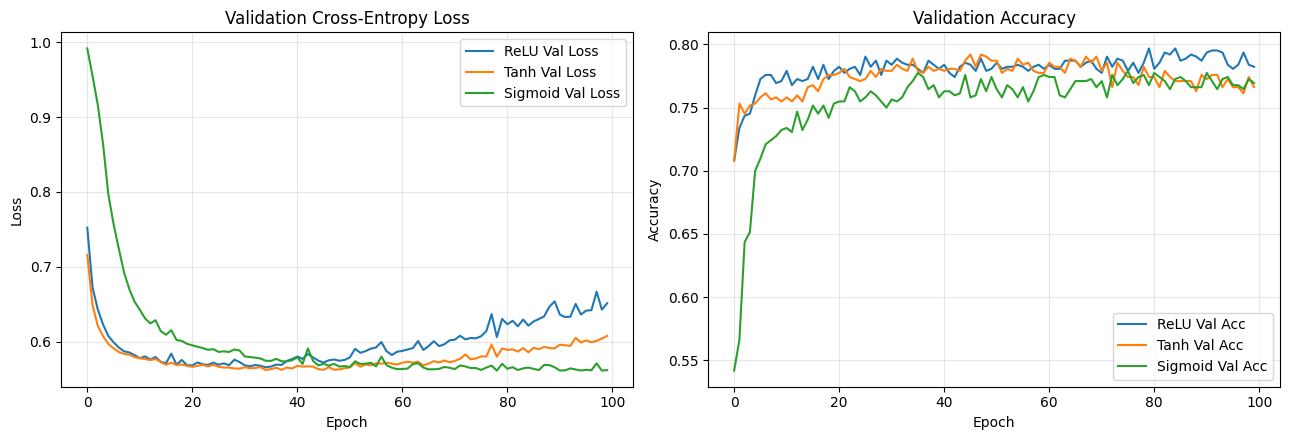

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, model in [('ReLU', ann_relu), ('Tanh', ann_tanh), ('Sigmoid', ann_sigmoid)]:
    axes[0].plot(model.history['val_loss'], label=f'{name} Val Loss')
    axes[1].plot(model.history['val_acc'], label=f'{name} Val Acc')

axes[0].set_title('Validation Cross-Entropy Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()